<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DL/blob/main/exp_22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 22: Independent Component Analysis (ICA)

In this experiment, we tackle the "cocktail-party problem" (separating mixed source signals) using Independent Component Analysis (ICA). We will compare the results of ICA with Principal Component Analysis (PCA) by recovering three synthetic source signals (a sine wave, a square wave, and a sawtooth wave) from random linear mixtures.

### Tasks:
1. Generate three independent source signals and mix them with a random matrix.
2. Apply `FastICA` from Scikit-learn to separate and recover the sources.
3. Apply `PCA` to the same mixtures for comparison.
4. Plot and compare the original, mixed, ICA-recovered, and PCA-recovered signals.
5. Measure the quality of the recovery by calculating correlation coefficients with the true sources.

## Task 1: Generate Source Signals and Mix Them
We will generate three distinct synthetic signals:
- A sine wave
- A square wave
- A sawtooth wave

Then, we will project them into an observed mixture space using a random $3 \times 3$ mixing matrix.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Set random seed for reproducibility
np.random.seed(42)

# 1. Generate sample data
n_samples = 2000
time = np.linspace(0, 8, n_samples)

s1 = np.sin(2 * time)  # Sine wave
s2 = np.sign(np.sin(3 * time))  # Square wave
s3 = signal.sawtooth(2 * np.pi * time)  # Sawtooth wave

# Combine sources into a matrix
S = np.c_[s1, s2, s3]
S += 0.2 * np.random.normal(size=S.shape)  # Add zero-mean Gaussian noise
S /= S.std(axis=0)  # Standardize sources

# 2. Mix data with a random mixing matrix
A = np.array([[1, 1, 1], [0.5, 2, 1.0], [1.5, 1.0, 2.0]])  # Mixing matrix
X = np.dot(S, A.T)  # Generate mixtures

## Task 2 & 3: Apply FastICA and PCA
We will apply `FastICA` to extract independent components, and `PCA` to extract orthogonal principal components from the mixed signal matrix `X`.

In [2]:
from sklearn.decomposition import FastICA, PCA

# Apply FastICA to recover the sources
ica = FastICA(n_components=3, random_state=42)
S_ica = ica.fit_transform(X)  # Reconstructed sources
A_ica = ica.mixing_  # Get estimated mixing matrix

# Apply PCA for comparison
pca = PCA(n_components=3, random_state=42)
S_pca = pca.fit_transform(X)  # Reconstructed sources using PCA

## Task 4: Visualization
We will now plot the Original Sources, the Mixed Signals, the ICA Reconstructed Sources, and the PCA Reconstructed Sources side-by-side to visually inspect the separation performance.

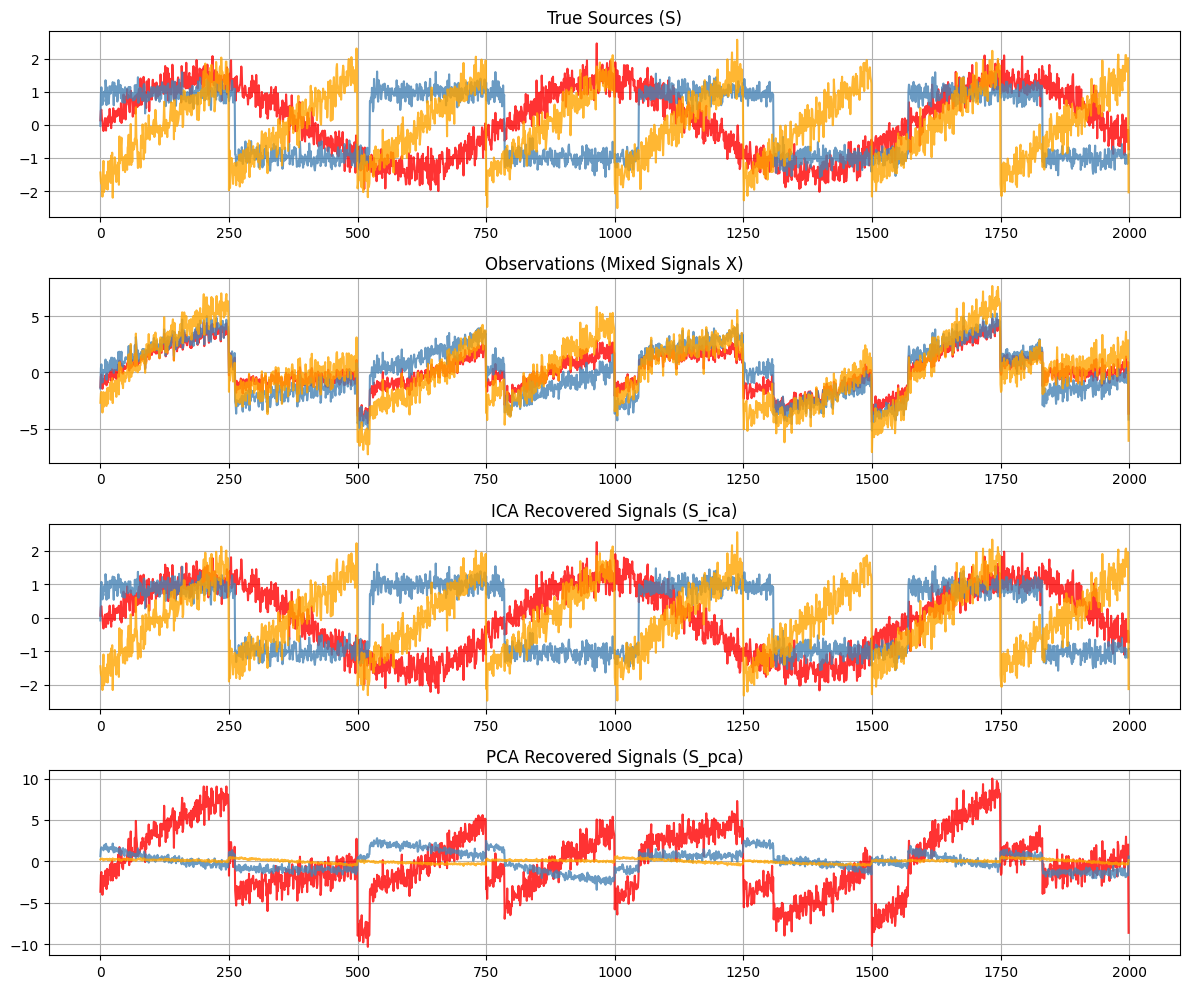

In [3]:
plt.figure(figsize=(12, 10))

models = [S, X, S_ica, S_pca]
names = [
    'True Sources (S)',
    'Observations (Mixed Signals X)',
    'ICA Recovered Signals (S_ica)',
    'PCA Recovered Signals (S_pca)'
]
colors = ['red', 'steelblue', 'orange']

for ii, (model, name) in enumerate(zip(models, names), 1):
    plt.subplot(4, 1, ii)
    plt.title(name)
    for sig, color in zip(model.T, colors):
        plt.plot(sig, color=color, alpha=0.8)
    plt.grid(True)

plt.tight_layout()
plt.show()

## Task 5: Measure Recovery Quality with Correlation
Because ICA recovers sources up to scaling and permutation (meaning the order of components or their sign might change), we will calculate the absolute maximum correlation coefficient between each true source and the recovered signals to verify separation quality.

In [4]:
def evaluate_recovery(true_sources, recovered_sources):
    """Calculates maximum absolute correlation of recovered sources to true sources."""
    n_sources = true_sources.shape[1]
    max_correlations = []
    for i in range(n_sources):
        corrs = []
        for j in range(n_sources):
            corr = np.corrcoef(true_sources[:, i], recovered_sources[:, j])[0, 1]
            corrs.append(abs(corr))
        max_correlations.append(max(corrs))
    return max_correlations

ica_corrs = evaluate_recovery(S, S_ica)
pca_corrs = evaluate_recovery(S, S_pca)

print("Recovery Quality (Absolute Correlation to True Sources):\n")
for idx, (ica_c, pca_c) in enumerate(zip(ica_corrs, pca_corrs), 1):
    print(f"Source {idx} (Signal {['Sine', 'Square', 'Sawtooth'][idx-1]}):")
    print(f"  ICA Recovery Correlation: {ica_c:.4f}")
    print(f"  PCA Recovery Correlation: {pca_c:.4f}\n")

Recovery Quality (Absolute Correlation to True Sources):

Source 1 (Signal Sine):
  ICA Recovery Correlation: 0.9969
  PCA Recovery Correlation: 0.7481

Source 2 (Signal Square):
  ICA Recovery Correlation: 0.9996
  PCA Recovery Correlation: 0.7837

Source 3 (Signal Sawtooth):
  ICA Recovery Correlation: 0.9974
  PCA Recovery Correlation: 0.6655

